# Wildfire Risk & Geospatial Analysis

## Objective

This analysis evaluates the 2022 wildfire risk predictions and enriches the property-level dataset with relevant 2020 Census features.

The analysis focuses on:
1. Evaluating the distribution and geographic patterns of the existing wildfire risk predictions.
2. Integrating Census tract-level information using property coordinates.
3. Engineering Census-derived features that may provide additional
   predictive information.

> **Public sharing notice:** The property-level and provided Census datasets originated from a technical assessment. They are not included in this notebook file, but code references their local filenames.


## Executive Summary 

**The problem.** This project evaluates an existing wildfire risk scoring model using approximately 500,000 U.S. properties with predicted risk scores ranging from 1 to 10 for 2022. The dataset contains predictions but no observed wildfire outcomes, making it necessary to integrate external data to evaluate predictive performance.

**The approach.** I integrated 2022 Monitoring Trends in Burn Severity (MTBS) wildfire perimeters with property coordinates to create an observed wildfire exposure indicator. I then evaluated model discrimination, investigated geographic effects, enriched properties with 2020 U.S. Census tract data, and tested whether additional features improved predictive performance.

**Previously recorded results (not verified in this cleaned notebook).**

| Result | Value |
|---|---|
| Properties analyzed | **499,992** |
| Properties inside 2022 wildfire perimeters | **920 (0.184%)** |
| Overall ROC-AUC | **0.976** (95% CI: 0.966–0.984) |
| PR-AUC | **0.051**, approximately **27.6×** the random baseline |
| Observed exposure rate, score 1 | **0.0009%** |
| Observed exposure rate, score 8 | **6.77%** |
| Wildfire-exposed properties captured by the highest-risk 5% | **95.0%** |
| Localized ROC-AUC (approximately 25-km neighborhoods) | **0.798** |
| Census tract matching rate | **99.99%** |

**Key Findings**

1. **Strong overall model discrimination.** The existing wildfire risk score demonstrated strong discrimination between properties inside and outside observed wildfire perimeters. The highest-risk 5% of properties captured approximately 95% of observed wildfire exposure cases, indicating substantial potential for risk-based prioritization.

2. **Risk-score distribution reflects observed exposure patterns.** Approximately 68.2% of properties received a risk score of 1. These properties exhibited extremely low observed wildfire exposure rates, supporting the model's ability to identify relatively low-risk geographic areas during the evaluation period.

3. **Geographic effects influence predictive performance.** Although overall ROC-AUC reached 0.976, performance decreased to 0.951 when evaluated within fire-affected counties and approximately **0.798** within localized 25-km neighborhoods. This suggests that the model's overall performance partly reflects its ability to distinguish wildfire-prone regions rather than exclusively identifying risk differences between nearby properties.

4. **Successful geospatial Census enrichment.** Property coordinates were spatially matched to 2020 U.S. Census tracts using GeoPandas, achieving a **99.99% match rate**. Housing, demographic, and socioeconomic attributes were integrated to support feature engineering and further predictive analysis.

5. **Additional Census features did not demonstrate improved generalization.** Initial county-grouped cross-validation showed that adding Census-derived features reduced mean ROC-AUC from **0.9777 to 0.7016** in the latest saved run. These results require a clean rerun and validation before publication.

**Principal limitation.** The evaluation is based on a single wildfire season, with 920 observed exposure cases associated with 33 wildfire events across 32 counties. Properties outside recorded wildfire perimeters are not necessarily low-risk, and geographic intersection does not establish structural damage. Results should therefore be interpreted as evidence of wildfire exposure discrimination rather than confirmed property-loss prediction.

**Structure.**

- **Section 1 — Wildfire Risk Validation:** Data quality assessment, risk-score distribution, external wildfire perimeter integration, model evaluation, and geographic sensitivity analysis.
- **Section 2 — Geospatial Census Enrichment:** Census data preparation, coordinate reference system alignment, spatial joins, demographic integration, and feature engineering.
- **Section 3 — Predictive Modelling:** Feature preparation, model comparison, county-grouped cross-validation, and evaluation of incremental predictive value.

**Conclusion.** This project demonstrates an end-to-end geospatial analytics workflow using Python, Pandas, GeoPandas, Scikit-learn, and external geographic datasets. The analysis highlights the importance of independent model validation, spatially aware evaluation, robust data integration, and testing whether engineered features improve predictive performance.



## Data Sources

### 1. Property-Level Wildfire Risk Dataset
The primary dataset contains approximately **500,000 U.S. properties**, including property ID, longitude, latitude, and predicted wildfire risk scores (1–10) for 2022.

**Availability:** Provided for a technical assessment; not included in this repository pending redistribution permission.

### 2. 2020 Census Tract-Level Data
Contains demographic, housing, and socioeconomic attributes used for geospatial enrichment and feature engineering, including population density, vacancy rates, housing composition, and income indicators.

**Availability:** The assessment-provided Census extract is not redistributed.

### 3. 2020 Census Tract Geographic Boundaries
**Source:** U.S. Census Bureau

The 2020 national Census tract shapefile was used to spatially match property coordinates to Census tract GEOIDs using GeoPandas.

- **Scale:** 1:500,000
- **Format:** Shapefile (~59 MB)
- **Source:** [U.S. Census Bureau — Cartographic Boundary Files](https://www.census.gov/geographies/mapping-files/2020/geo/carto-boundary-file.html)

### 4. Historical Wildfire Perimeters (MTBS)
**Source:** Monitoring Trends in Burn Severity (MTBS)

2022 wildfire perimeter data was used to validate predicted risk scores against observed geographic wildfire exposure through spatial joins.

- **Exposure = 1:** Property inside a wildfire perimeter
- **Exposure = 0:** Property outside recorded perimeters
- **Source:** [MTBS Official Website](https://www.mtbs.gov/)

**Note:** Wildfire perimeter intersection indicates geographic exposure, not confirmed property damage.

### Data Availability
Assessment-provided datasets are excluded from the public repository pending permission. Public geographic data sources are linked above. Reproducing the original results requires access to the underlying assessment data.


## Reproducibility and execution instructions

1. Obtain authorized copies of the three required local datasets. They are **not included** in this public repository.
2. Install packages using `requirements.txt` (or uncomment the installation cell below).
3. Set `DATA_DIR` in the setup cell if your files are stored in a different folder.
4. In Jupyter, choose **Kernel → Restart Kernel and Run All Cells**. The MTBS download requires internet access and may take time.
5. Inspect errors, regenerated figures, and all metrics. **Previously recorded numerical findings in the narrative are historical and must be checked against the new output before publication.**

**Interpretation:** The `burned_2022` column denotes a property point intersecting a mapped MTBS wildfire perimeter; it does not prove property damage, nor does a non-intersection prove absence of damage. The 1–10 risk score is ordinal, not a calibrated probability.

In [ ]:
 %pip install pandas geopandas matplotlib plotly numpy scipy scikit-learn openpyxl pyogrio requests

In [107]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# Keep authorized source files beside this notebook, or set DATA_DIR to their directory.
DATA_DIR = Path(".")
required_files = ["wildfire_risk_data_set.xlsx", "census_tract_level_data_2020.csv", "cb_2020_us_tract_500k.zip"]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError("Required local input files not found: " + ", ".join(missing_files) + ". Set DATA_DIR to the folder containing authorized copies before continuing.")

# Task 1: Evaluation of Existing Wildfire Risk Predictions

The objective of this section is to examine the quality, distribution, and geographic behavior of the wildfire risk predictions.
Observed wildfire outcomes are not included in the dataset provided, so traditional predictive-performance
metrics such as precision, recall, and ROC-AUC cannot be calculated from the supplied data alone.
Sections 1.1 to 1.6 therefore characterise the predictions themselves, and Section 1.7 introduces an
external source of observed 2022 wildfire outcomes so that these metrics can be calculated after all.

## 1.1 Load and Inspect Data

Firstly, I loaded the dataset provided, then reviewed the structure, dimensions and the data types.

In [3]:
wildfire = pd.read_excel(DATA_DIR / "wildfire_risk_data_set.xlsx", sheet_name = "wildfire_risk_data_set")
score_details = pd.read_excel(DATA_DIR / "wildfire_risk_data_set.xlsx", sheet_name = "score_details")

In [4]:
wildfire.head()

,id,longitude,latitude,risk_score_prediction
0,1,-114.47716,34.012841,1
1,2,-114.477137,34.012848,1
2,3,-114.475225,34.01136,1
3,4,-109.659955,31.883023,1
4,5,-104.252778,32.406863,1


In [5]:
wildfire.shape

(500000, 4)

In [6]:
wildfire.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 4 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   id                     500000 non-null  int64 
 1   longitude              500000 non-null  object
 2   latitude               500000 non-null  object
 3   risk_score_prediction  500000 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 15.3+ MB


In [7]:
score_details

,risk_score,risk_level
0,1,very low
1,2,low
2,3,medium
3,4,medium
4,5,high
5,6,high
6,7,very high
7,8,very high
8,9,very high
9,10,very high


## Initial Observations

The wildfire dataset contains 500,000 property records and four variables: property ID, longitude, latitude, and the predicted wildfire risk score.

All four columns contain 500,000 non-null values. Property ID and risk score are stored as integers, while longitude and latitude are currently stored as object data types. I will further investigate the data types while doing the data quality checks.

The `score_details` worksheet contains the mapping between the predicted scores (1–10) and the corresponding risk levels from very low to very high.

## 1.2 Data Quality Assessment

Before analyzing the wildfire risk predictions, I checked the dataset for missing values, duplicate property IDs, invalid risk scores, and potential issues with the geographic coordinates.

In [8]:
wildfire.isnull().sum()

id                       0
longitude                0
latitude                 0
risk_score_prediction    0
dtype: int64

In [9]:
wildfire.duplicated().sum()

np.int64(0)

In [10]:
wildfire["id"].duplicated().sum()

np.int64(0)

In [11]:
wildfire["risk_score_prediction"].value_counts().sort_index()

risk_score_prediction
1     341174
2      71742
3      36625
4      20385
5      10859
6       7375
7       6184
8       3725
9       1649
10       282
Name: count, dtype: int64

In [12]:
wildfire["longitude"].map(type).value_counts()

longitude
<class 'float'>    499996
<class 'str'>           2
<class 'int'>           2
Name: count, dtype: int64

In [13]:
wildfire["latitude"].map(type).value_counts()

latitude
<class 'float'>    499997
<class 'int'>           2
<class 'str'>           1
Name: count, dtype: int64

In [14]:
longitude_numeric = pd.to_numeric(wildfire["longitude"], errors="coerce")

latitude_numeric = pd.to_numeric(wildfire["latitude"], errors="coerce")

print("Longitude values that cannot be converted:",
      longitude_numeric.isna().sum())

print("Latitude values that cannot be converted:",
      latitude_numeric.isna().sum())

Longitude values that cannot be converted: 2
Latitude values that cannot be converted: 1


In [15]:
wildfire[longitude_numeric.isna()]

,id,longitude,latitude,risk_score_prediction
118102,118103,/,38.644472,1
403463,403464,/,35.25407,2


In [16]:
wildfire[latitude_numeric.isna()]

,id,longitude,latitude,risk_score_prediction
403477,403478,-113.992375,/,2


In [17]:
wildfire["longitude"] = pd.to_numeric(wildfire["longitude"], errors="coerce")

wildfire["latitude"] = pd.to_numeric(wildfire["latitude"], errors="coerce")

wildfire[["longitude", "latitude"]].dtypes

longitude    float64
latitude     float64
dtype: object

In [18]:
wildfire[["longitude", "latitude"]].isnull().sum()

longitude    2
latitude     1
dtype: int64

In [19]:
wildfire_clean = wildfire.dropna(subset=["longitude", "latitude"]).copy()
wildfire_clean.shape

(499997, 4)

In [20]:
print("Longitude range:", wildfire_clean["longitude"].min(),"to", wildfire_clean["longitude"].max())

print("Latitude range:", wildfire_clean["latitude"].min(),"to", wildfire_clean["latitude"].max())

invalid_longitude = ~wildfire_clean["longitude"].between(-180, 180)
invalid_latitude = ~wildfire_clean["latitude"].between(-90, 90)

print("Invalid longitude:", invalid_longitude.sum())
print("Invalid latitude:", invalid_latitude.sum())

Longitude range: -124.57382 to 30.1719051
Latitude range: -95.4786413 to 49.0016646
Invalid longitude: 0
Invalid latitude: 5


In [21]:
wildfire_clean[invalid_latitude]

,id,longitude,latitude,risk_score_prediction
251582,251583,30.146114,-95.451675,1
251583,251584,30.148824,-95.451941,1
251584,251585,30.171483,-95.477986,1
251585,251586,30.171905,-95.478641,1
251586,251587,30.164417,-95.472856,1


In [22]:
wildfire_clean = wildfire_clean[wildfire_clean["latitude"].between(-90, 90) & wildfire_clean["longitude"].between(-180, 180)].copy()

wildfire_clean.shape

(499992, 4)

### Data Quality Findings

The dataset contained no null values initially, no duplicate property IDs, and no fully duplicated rows. All predicted risk scores were within the expected range of 1 to 10.

During the coordinate check, longitude and latitude were stored as object data types. Further investigation showed that most values were numeric, but three records contained "/" as a coordinate placeholder: two in longitude and one in latitude. These placeholders were converted to missing values during numeric conversion. 

An additional coordinate-range check identified five records with latitude values below -90 as the range being -90 to 90. 

For geographic analysis and Census tract matching, I created `wildfire_clean` containing only records with non-missing coordinates within valid global longitude and latitude ranges. The original dataset, however, was retained for non-geographic analysis.

## 1.3 Risk Score Distribution

I examined the frequency and percentage of properties assigned to each wildfire risk score to understand how the model distributes predicted risk across the dataset.

In [23]:
risk_counts = (wildfire["risk_score_prediction"].value_counts().sort_index())

risk_counts

risk_score_prediction
1     341174
2      71742
3      36625
4      20385
5      10859
6       7375
7       6184
8       3725
9       1649
10       282
Name: count, dtype: int64

In [24]:
risk_percentages = (wildfire["risk_score_prediction"].value_counts(normalize=True).sort_index().mul(100))

risk_percentages

risk_score_prediction
1     68.2348
2     14.3484
3      7.3250
4      4.0770
5      2.1718
6      1.4750
7      1.2368
8      0.7450
9      0.3298
10     0.0564
Name: proportion, dtype: float64

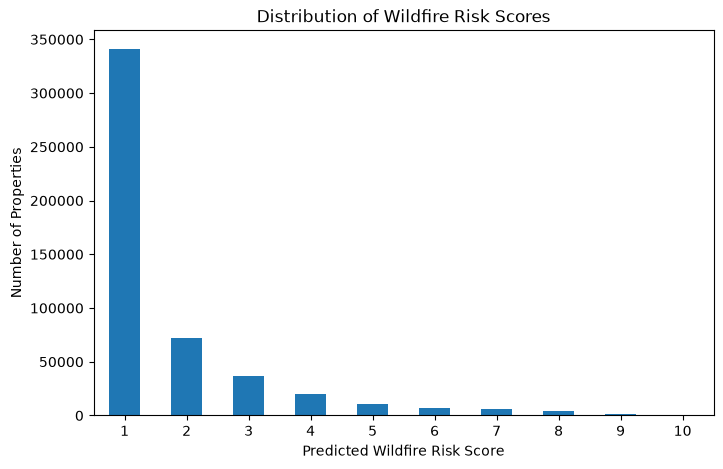

In [25]:
plt.figure(figsize=(8, 5))

risk_counts.plot(kind="bar")

plt.title("Distribution of Wildfire Risk Scores")
plt.xlabel("Predicted Wildfire Risk Score")
plt.ylabel("Number of Properties")
plt.xticks(rotation=0)

plt.show()

### Risk Score Distribution Findings

The predicted wildfire risk scores are strongly concentrated at the lower end of the 1–10 scale. Approximately 68.2% of properties received a risk score of 1, while 14.3% received a score of 2. The number of properties decreases as the predicted risk score increases, with only a small proportion receiving scores in the highest-risk range.

This indicates that the model assigns low predicted wildfire risk to the majority of properties in the dataset. However, the concentration of predictions at lower scores should not by itself be interpreted as poor model performance, since no observed wildfire outcome or ground-truth label is provided for comparison.

## 1.4 Risk Level Distribution

The `score_details` worksheet maps each predicted wildfire risk score from 1–10 to a corresponding risk-level category. I merged this lookup table with the property-level dataset to analyze the distribution of properties across the broader risk categories.

In [26]:
wildfire_with_levels = wildfire.merge(score_details,
    left_on="risk_score_prediction",
    right_on="risk_score",
    how="left")

wildfire_with_levels.head()

,id,longitude,latitude,risk_score_prediction,risk_score,risk_level
0,1,-114.477160,34.012841,1,1,very low
1,2,-114.477137,34.012848,1,1,very low
2,3,-114.475225,34.011360,1,1,very low
3,4,-109.659955,31.883023,1,1,very low
4,5,-104.252778,32.406863,1,1,very low


In [27]:
wildfire_with_levels["risk_level"].isnull().sum()

np.int64(0)

In [28]:
risk_level_counts = wildfire_with_levels["risk_level"].value_counts()

risk_level_counts

risk_level
very low     341174
low           71742
medium        57010
high          18234
very high     11840
Name: count, dtype: int64

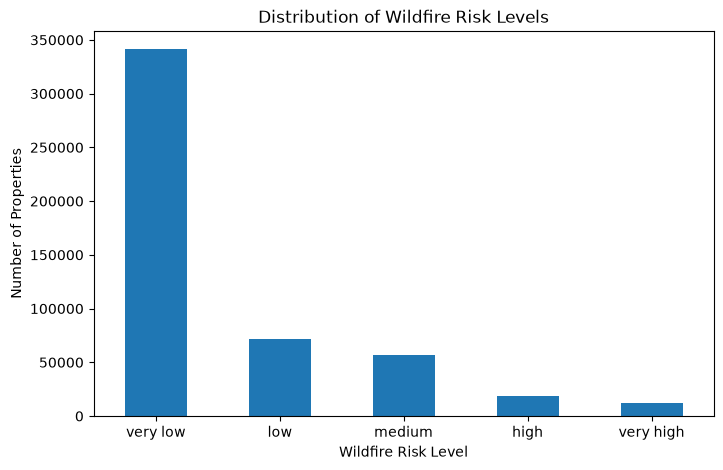

In [29]:
plt.figure(figsize=(8, 5))

risk_level_counts.plot(kind="bar")

plt.title("Distribution of Wildfire Risk Levels")
plt.xlabel("Wildfire Risk Level")
plt.ylabel("Number of Properties")
plt.xticks(rotation=0)

plt.show()

### Risk Level Distribution Findings

The risk-level distribution is heavily concentrated in the lower-risk categories. Overall, the model assigns most properties to the lower-risk categories, while relatively few properties receive high or very high risk classifications. This is particularly useful business insight to present to a stakeholder for better understanding.

## 1.5 Geographic Distribution

To examine the geographic pattern of the model predictions, I used the cleaned property dataset containing valid longitude and latitude coordinates. The geographic distribution helps identify whether higher predicted wildfire risk is concentrated in particular areas of the United States.

In [ ]:

import plotly.express as px

# Prepare data for interactive visualization
map_df = wildfire_clean[
    ["id", "longitude", "latitude", "risk_score_prediction"]
].dropna().copy()

# Create interactive geographic scatter plot
fig = px.scatter_map(
    map_df,
    lat="latitude",
    lon="longitude",
    color="risk_score_prediction",
    color_continuous_scale="YlOrRd",
    range_color=(1, 10),
    zoom=3,
    center={"lat": 39, "lon": -98},
    opacity=0.6,
    hover_data={
        "id": True,
        "latitude": ":.4f",
        "longitude": ":.4f",
        "risk_score_prediction": True
    },
    labels={
        "risk_score_prediction": "Wildfire Risk Score"
    },
    title="Interactive Geographic Distribution of Wildfire Risk"
)

fig.update_traces(marker={"size": 4})

fig.update_layout(
    map_style="carto-positron",
    height=650,
    margin={"r": 0, "t": 60, "l": 0, "b": 0},
    coloraxis_colorbar={
        "title": "Risk Score"
    }
)

fig.show()


### Geographic Distribution Findings

The geographic distribution shows that predicted wildfire risk is not uniform across the dataset. Higher risk scores appear more concentrated in portions of the western United States, while many other areas contain predominantly lower-risk predictions.

The visualization also reveals a small number of geographically unusual observations outside the main concentration of U.S. properties. Although these coordinates fall within globally valid longitude and latitude ranges, their locations may not be consistent with the expected geographic coverage of the dataset. 

## 1.6 Task 1 Findings and Limitations

The analysis shows that the model's predicted wildfire risk is strongly concentrated at the lower end of the risk scale. Approximately 68.2% of properties received a risk score of 1, and the number of properties generally decreases as the predicted risk score increases. When grouped using the provided risk-level definitions, most properties fall within the very low and low risk categories, while high and very high risk properties represent a relatively small proportion of the dataset.

## 1.7 External Validation Using Observed 2022 Wildfire Outcomes

The analysis so far describes how the model distributes its predictions, but it does not measure whether
those predictions are correct. The provided dataset contains no observed wildfire outcome, so no label
exists within it against which the scores can be judged.

Rather than stopping at that limitation, I sourced an external ground truth. The risk scores are
predictions **for the year 2022**, which means a validation against wildfires that actually occurred in
2022 is correctly ordered in time: the prediction precedes the outcome it is being judged against.

I therefore integrate a third-party record of 2022 burned areas, label each property according to whether
it fell inside a 2022 wildfire perimeter, and use that label to compute the discrimination and calibration
metrics that could not be computed from the provided data alone.

In [32]:
import os
import numpy as np
import requests

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)

### 1.7.1 Data Source: MTBS Burned Area Boundaries

I used **Monitoring Trends in Burn Severity (MTBS)**, a joint program of the USGS and the USDA Forest
Service that maps the perimeter and severity of large fires across all US states from 1984 onward.
MTBS is the standard reference dataset for historical US fire extent, and because it is consistently
mapped from Landsat imagery it is more reliable for year-over-year comparison than incident-reported
perimeters.

**Source:** USGS / USDA Forest Service, Monitoring Trends in Burn Severity, national burned area
boundaries shapefile.

Two properties of this dataset matter for the analysis and are handled explicitly below:

1. MTBS only maps fires above a size threshold (roughly 1,000 acres in the western US and 500 acres in the
   east). Small fires that still destroy homes are not represented, so the label undercounts loss events.
2. MTBS records prescribed burns and other intentional fires alongside wildfires. These must be filtered
   out, since a controlled burn is not the outcome the risk model is predicting.

In [33]:
import zipfile

# Official MTBS wildfire perimeter archive
MTBS_URL = (
    "https://edcintl.cr.usgs.gov/downloads/sciweb1/shared/MTBS_Fire/data/"
    "composite_data/burned_area_extent_shapefile/"
    "mtbs_perimeter_data.zip"
)

MTBS_ZIP = "mtbs_perimeter_data.zip"
TEMP_ZIP = MTBS_ZIP + ".part"

# Download only if a valid archive is not already available
if not os.path.exists(MTBS_ZIP) or not zipfile.is_zipfile(MTBS_ZIP):

    print("Downloading MTBS wildfire perimeter data...")

    try:
        with requests.get(
            MTBS_URL,
            stream=True,
            timeout=(30, 120)
        ) as response:

            response.raise_for_status()

            with open(TEMP_ZIP, "wb") as file:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file.write(chunk)

        # Verify the downloaded archive
        if not zipfile.is_zipfile(TEMP_ZIP):
            raise ValueError("Downloaded file is not a valid ZIP archive.")

        # Replace the destination only after validation
        os.replace(TEMP_ZIP, MTBS_ZIP)

        print("Download completed successfully.")

    finally:
        if os.path.exists(TEMP_ZIP):
            os.remove(TEMP_ZIP)

else:
    print("Valid MTBS archive already exists. Skipping download.")

# Display archive size
size_mb = os.path.getsize(MTBS_ZIP) / 1e6
print(f"Archive size: {size_mb:.1f} MB")


Valid MTBS archive already exists. Skipping download.
Archive size: 389.9 MB



### Downloading Historical Wildfire Perimeter Data

To evaluate the predicted wildfire risk scores against observed outcomes, historical wildfire perimeter data was obtained from the **Monitoring Trends in Burn Severity (MTBS)** program.

The dataset contains geographic boundaries of recorded wildfire events and is used to identify properties located within wildfire perimeters during 2022.

The archive is downloaded using Python's `requests` library with streamed processing to handle the large file efficiently. Existing valid downloads are reused to avoid unnecessary network requests.

**Purpose:** Establish an observed wildfire exposure indicator for independent model validation.

**Source:** [Monitoring Trends in Burn Severity (MTBS)](https://www.mtbs.gov/)


In [34]:
fires = gpd.read_file(MTBS_ZIP)

print("Total MTBS records:", len(fires))
fires[["event_id", "incid_name", "incid_type", "ig_date", "burnbndac"]].head()

Total MTBS records: 30930


,event_id,incid_name,incid_type,ig_date,burnbndac
0,UT4176411148820121004,HELLS HOLLOW,Prescribed Fire,2012-10-04,4756
1,WA4796812059020120908,KLONE PEAK,Wildfire,2012-09-08,1634
2,WA4797012073420120908,BASALT,Wildfire,2012-09-08,1704
3,WA4805112058820120908,PYRAMID,Wildfire,2012-09-08,1962
4,WA4788612026820120908,FIRST CREEK,Wildfire,2012-09-08,1434


In [35]:
fires["ig_date"] = pd.to_datetime(fires["ig_date"], errors="coerce")
fires["fire_year"] = fires["ig_date"].dt.year

fires[fires["fire_year"] == 2022]["incid_type"].value_counts()

incid_type
Prescribed Fire    638
Wildfire           530
Other                9
Name: count, dtype: int64

### Filtering to Wildfires

The incident-type breakdown shows that a majority of the 2022 MTBS records are **prescribed fires** rather
than wildfires. Prescribed burns are deliberate and controlled, and they occur in locations chosen
precisely because burning is considered safe there. Including them would contaminate the label with events
that are not the outcome the risk model predicts, and would bias the validation in an unpredictable
direction.

I therefore restrict the ground truth to records where `incid_type` is `Wildfire`.

In [36]:
fires_2022 = fires[
    (fires["fire_year"] == 2022) & (fires["incid_type"] == "Wildfire")
].copy()

print("All MTBS events in 2022:", int((fires["fire_year"] == 2022).sum()))
print("Of which are wildfires:", len(fires_2022))
print("Total burned acres:", format(fires_2022["burnbndac"].sum(), ",.0f"))
print("Largest fire:", fires_2022.loc[fires_2022["burnbndac"].idxmax(), "incid_name"])

All MTBS events in 2022: 1177
Of which are wildfires: 530
Total burned acres: 6,856,430
Largest fire: HERMITS PEAK


### Preparing Property Geometries and Aligning Coordinate Systems

This section sits within Task 1 because it evaluates the model, and it deliberately does not depend on the
Census work that follows. I therefore build the property point geometries directly from `wildfire_clean`,
the cleaned coordinate dataset produced in Section 1.2, so that this validation stands on its own and the
notebook runs correctly from top to bottom.

As with any spatial join, the points and polygons must share a coordinate reference system. The property
coordinates are interpreted as WGS84 (EPSG:4326) and then aligned to the CRS of the MTBS perimeters.

In [37]:
props_geo = gpd.GeoDataFrame(
    wildfire_clean[["id", "longitude", "latitude", "risk_score_prediction"]].copy(),
    geometry=gpd.points_from_xy(
        wildfire_clean["longitude"], wildfire_clean["latitude"]
    ),
    crs="EPSG:4326",
)

print("MTBS CRS:", fires_2022.crs)
print("Property CRS:", props_geo.crs)

props_geo = props_geo.to_crs(fires_2022.crs)

print("Aligned:", props_geo.crs == fires_2022.crs)

MTBS CRS: EPSG:4269
Property CRS: EPSG:4326
Aligned: True


### 1.7.2 Labelling Properties With Observed Wildfire Outcomes

I spatially joined the property points against the 2022 wildfire perimeters. A property is labelled as
burned when its point falls within a mapped perimeter.

I used an inner join and then flagged the matched property IDs, rather than a left join. A property that
sits inside two overlapping perimeters would otherwise produce duplicate rows and inflate the property
count. Collecting the set of matched IDs avoids this entirely.

In [38]:
burn_hits = gpd.sjoin(
    props_geo,
    fires_2022[["event_id", "incid_name", "geometry"]],
    how="inner",
    predicate="within",
)

burned_ids = set(burn_hits["id"])

evaluation = props_geo.drop(columns="geometry").reset_index(drop=True)
evaluation["burned_2022"] = evaluation["id"].isin(burned_ids).astype(int)

print("Properties inside a 2022 wildfire perimeter:", int(evaluation["burned_2022"].sum()))
print("Base rate: {:.4f}%".format(evaluation["burned_2022"].mean() * 100))
print("Distinct fires containing at least one property:", burn_hits["event_id"].nunique())

# Every metric that follows requires at least one positive case. Failing loudly here is
# clearer than allowing the downstream metrics to raise less obvious errors.
if evaluation["burned_2022"].sum() == 0:
    raise ValueError(
        "No properties matched a 2022 wildfire perimeter. Check the CRS alignment "
        "and the incident-type filter before continuing."
    )

Properties inside a 2022 wildfire perimeter: 920
Base rate: 0.1840%
Distinct fires containing at least one property: 33


The base rate is very low, which is expected: wildfire is a rare event at the level of an individual
property in a single year. A low base rate does not prevent evaluation, but it does mean accuracy is a
meaningless metric here, since a model predicting "never burns" would score above 99%. The metrics used
below are therefore rank-based and threshold-free, which is the appropriate choice for a rare-event
ranking model.

### 1.7.3 Observed Burn Rate by Predicted Risk Score

The most direct test of the model is whether the observed rate of burning rises with the predicted score.
This is a risk-ranking check: it asks whether the ordinal scale means what it claims to mean.

In [39]:
burn_by_score = evaluation.groupby("risk_score_prediction").agg(
    properties=("burned_2022", "size"),
    burned=("burned_2022", "sum"),
)

burn_by_score["burn_rate_pct"] = (
    burn_by_score["burned"] / burn_by_score["properties"] * 100
)

overall_rate = evaluation["burned_2022"].mean() * 100
burn_by_score["lift_vs_overall"] = (burn_by_score["burn_rate_pct"] / overall_rate).round(2)

burn_by_score

,properties,burned,burn_rate_pct,lift_vs_overall
risk_score_prediction,,,,
1,341168,3,0.000879,0.00
2,71740,2,0.002788,0.02
3,36625,4,0.010922,0.06
4,20385,37,0.181506,0.99
5,10859,133,1.224790,6.66
6,7375,126,1.708475,9.29
7,6184,236,3.816300,20.74
8,3725,252,6.765101,36.77
9,1649,111,6.731352,36.58


The apparent dip at the top of the scale needs a confidence interval before it can be interpreted. Scores 9
and 10 contain only 1,649 and 282 properties respectively, so their observed rates are estimated from very
few events.

In [40]:
top_scores = burn_by_score.loc[7:].copy()

rate = top_scores["burned"] / top_scores["properties"]
standard_error = np.sqrt(rate * (1 - rate) / top_scores["properties"])

top_scores["rate_pct"] = (rate * 100).round(2)
top_scores["ci_low_pct"] = ((rate - 1.96 * standard_error).clip(lower=0) * 100).round(2)
top_scores["ci_high_pct"] = ((rate + 1.96 * standard_error) * 100).round(2)

top_scores[["properties", "burned", "rate_pct", "ci_low_pct", "ci_high_pct"]]

,properties,burned,rate_pct,ci_low_pct,ci_high_pct
risk_score_prediction,,,,,
7,6184,236,3.82,3.34,4.29
8,3725,252,6.77,5.96,7.57
9,1649,111,6.73,5.52,7.94
10,282,16,5.67,2.97,8.37


The intervals for scores 8, 9 and 10 overlap substantially. The burn rate rises monotonically through score
8 and then **plateaus**; the apparent decline at 9 and 10 is small-sample noise, not evidence that the
highest scores are less dangerous. The correct statement is that the model separates cleanly up to score 8
and cannot be shown to distinguish 8, 9 and 10 from one another on a single year of data.

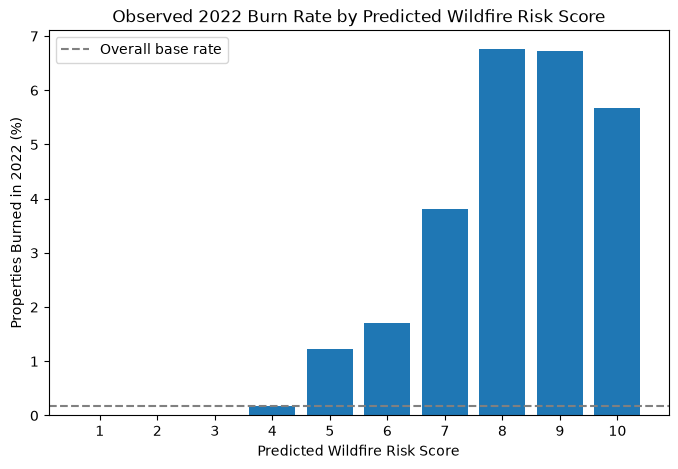

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(burn_by_score.index, burn_by_score["burn_rate_pct"])
plt.axhline(overall_rate, linestyle="--", color="grey", label="Overall base rate")

plt.title("Observed 2022 Burn Rate by Predicted Wildfire Risk Score")
plt.xlabel("Predicted Wildfire Risk Score")
plt.ylabel("Properties Burned in 2022 (%)")
plt.xticks(burn_by_score.index)
plt.legend()

plt.show()

### 1.7.4 Discrimination Metrics

With an observed outcome available, the standard evaluation metrics can now be calculated. I report
ROC-AUC, which measures the probability that a randomly chosen burned property received a higher score
than a randomly chosen unburned one, and average precision (PR-AUC), which is the more informative summary
under severe class imbalance.

In [42]:
y_true = evaluation["burned_2022"].values
y_score = evaluation["risk_score_prediction"].values

roc_auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC (average precision):", round(pr_auc, 5))
print("Base rate (PR-AUC of a random model):", round(y_true.mean(), 5))
print("PR-AUC lift over random: {:.1f}x".format(pr_auc / y_true.mean()))

ROC-AUC: 0.9761
PR-AUC (average precision): 0.05087
Base rate (PR-AUC of a random model): 0.00184
PR-AUC lift over random: 27.6x


**How to read these numbers.**

- **ROC-AUC** answers: take one property that burned in 2022 and one that did not, both at random. How
  often did the model give the burned one the higher score? 0.5 means a coin flip and the model carries no
  information; 1.0 means perfect separation. Anything meaningfully above 0.5 is real signal.
- **Accuracy is deliberately not reported.** With a base rate of 0.18%, a model that predicted "nothing
  ever burns" would be over 99% accurate and completely useless. This is why the metrics used here are
  rank-based.
- **PR-AUC (average precision)** is the honest companion under this kind of imbalance. Its natural
  reference point is not 0.5 but the base rate itself, which is what a random model would achieve. The
  ratio printed above is therefore the more interpretable figure: how many times better than random the
  score is at concentrating the properties that actually burned.

### Confidence Interval With Spatial Clustering

A confidence interval computed naively over 500,000 rows would be misleadingly narrow. Properties are
spatially clustered and wildfire outcomes are strongly spatially correlated: a single fire event
simultaneously determines the label for every property inside its perimeter. The effective sample size is
therefore much closer to the number of independent geographic areas than to the number of properties.

I use a block bootstrap that resamples **half-degree geographic cells** (roughly 55 km, larger than most
individual fire footprints) rather than individual properties. This preserves the dependence structure and
produces an honest interval.

In [43]:
evaluation["grid_cell"] = (
    (evaluation["latitude"] // 0.5).astype(int).astype(str)
    + "_"
    + (evaluation["longitude"] // 0.5).astype(int).astype(str)
)

cell_groups = {
    cell: group.index.values
    for cell, group in evaluation.groupby("grid_cell")
}
cells_available = np.array(list(cell_groups.keys()))

print("Spatial blocks:", len(cells_available))

rng = np.random.default_rng(42)
bootstrap_aucs = []

for _ in range(200):
    sampled = rng.choice(cells_available, size=len(cells_available), replace=True)
    rows = np.concatenate([cell_groups[c] for c in sampled])

    y_b = evaluation["burned_2022"].values[rows]
    s_b = evaluation["risk_score_prediction"].values[rows]

    if 0 < y_b.sum() < len(y_b):
        bootstrap_aucs.append(roc_auc_score(y_b, s_b))

print("Cluster bootstrap replicates:", len(bootstrap_aucs))
if not bootstrap_aucs:
    raise ValueError("No valid bootstrap samples; cannot calculate confidence interval.")

print(
    "95% CI for ROC-AUC: [{:.3f}, {:.3f}]".format(
        np.percentile(bootstrap_aucs, 2.5), np.percentile(bootstrap_aucs, 97.5)
    )
)

Spatial blocks: 1434
Cluster bootstrap replicates: 200
95% CI for ROC-AUC: [0.966, 0.984]


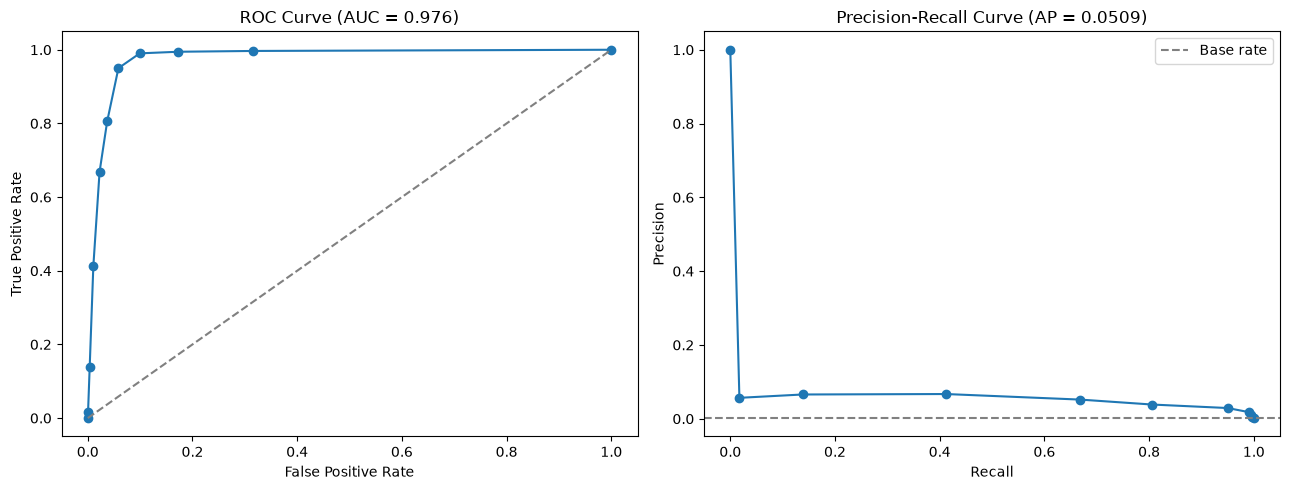

In [44]:
fpr, tpr, _ = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, marker="o")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set_title("ROC Curve (AUC = {:.3f})".format(roc_auc))
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].plot(recall, precision, marker="o")
axes[1].axhline(y_true.mean(), linestyle="--", color="grey", label="Base rate")
axes[1].set_title("Precision-Recall Curve (AP = {:.4f})".format(pr_auc))
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### 1.7.5 Cumulative Gain

The gain curve translates the metrics above into the operational question an insurer actually asks: if the
book is ranked by predicted risk, what share of the properties that actually burned is captured within the
riskiest slice of the portfolio?

In [45]:
order = np.argsort(-y_score, kind="stable")
y_ordered = y_true[order]

cumulative_capture = np.cumsum(y_ordered) / y_ordered.sum()
population_share = np.arange(1, len(y_ordered) + 1) / len(y_ordered)

for threshold in [0.01, 0.05, 0.10, 0.20]:
    cut = int(threshold * len(y_ordered))
    print(
        "Top {:>3.0f}% by risk score captures {:5.1f}% of properties that burned".format(
            threshold * 100, cumulative_capture[cut - 1] * 100
        )
    )

Top   1% by risk score captures  41.0% of properties that burned
Top   5% by risk score captures  95.0% of properties that burned
Top  10% by risk score captures  99.0% of properties that burned
Top  20% by risk score captures  99.7% of properties that burned


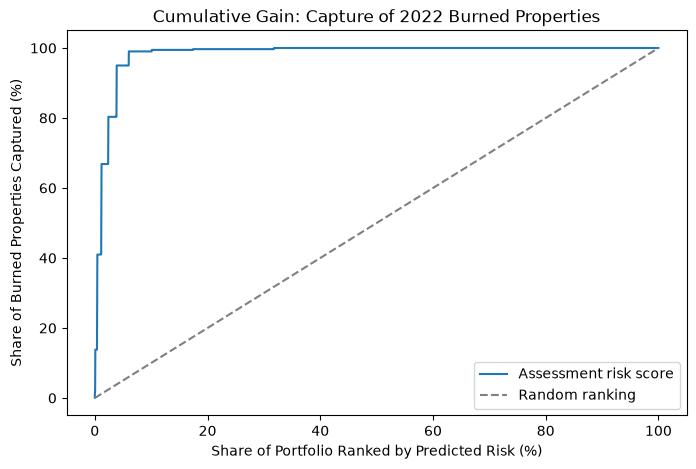

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(population_share * 100, cumulative_capture * 100, label="Assessment risk score")
plt.plot([0, 100], [0, 100], linestyle="--", color="grey", label="Random ranking")

plt.title("Cumulative Gain: Capture of 2022 Burned Properties")
plt.xlabel("Share of Portfolio Ranked by Predicted Risk (%)")
plt.ylabel("Share of Burned Properties Captured (%)")
plt.legend()

plt.show()

**How to read this chart.** The diagonal is what random ranking achieves: inspect 10% of the portfolio and
find 10% of the losses. The plotted curve is the model. The vertical distance between them is the value the
model adds.

This is the form in which the result matters commercially. An insurer cannot re-inspect 500,000 properties,
but it can act on the riskiest few percent — reprice, require mitigation, or decline. The gain curve states
exactly how much of the real loss exposure that action would reach.

### 1.7.6 Sensitivity to Perimeter Edge Effects

A property immediately outside a mapped perimeter may still have been damaged, and perimeter geometry is
itself an approximation derived from satellite imagery. To confirm the result is not an artefact of
treating the boundary as exact, I repeated the join with a 100 metre buffer around each perimeter.

The buffer requires a projected CRS with metre units, so I reprojected to US Contiguous Albers Equal Area
(EPSG:5070) for this step. Alaska and Hawaii are distorted under this projection, so the check is
indicative rather than exact for those states.

In [47]:
ALBERS = "EPSG:5070"

props_albers = props_geo.to_crs(ALBERS)
fires_albers = fires_2022.to_crs(ALBERS)

fires_buffered = fires_albers[["event_id", "geometry"]].copy()
fires_buffered["geometry"] = fires_albers.buffer(100)

buffer_hits = gpd.sjoin(
    props_albers[["id", "geometry"]],
    fires_buffered,
    how="inner",
    predicate="within",
)

buffered_ids = set(buffer_hits["id"])
evaluation["burned_2022_buffered"] = evaluation["id"].isin(buffered_ids).astype(int)

print("Strict perimeter matches:", int(evaluation["burned_2022"].sum()))
print("With 100m buffer:", int(evaluation["burned_2022_buffered"].sum()))
if evaluation["burned_2022_buffered"].nunique() == 2:
    print("ROC-AUC with buffered label:", round(roc_auc_score(evaluation["burned_2022_buffered"], y_score), 4))
else:
    print("Buffered ROC-AUC unavailable: only one outcome class present.")

Strict perimeter matches: 920
With 100m buffer: 962
ROC-AUC with buffered label: 0.9744


### 1.7.7 At What Spatial Scale Does the Model Discriminate?

A ROC-AUC of 0.976 is high enough to warrant scrutiny before it is reported. Part of that performance may
come from the model doing something comparatively easy — separating fire-prone regions of the western US
from regions that essentially never burn — rather than the harder task an underwriter actually needs, which
is separating two properties a few miles apart.

To separate these, I recompute the AUC on progressively narrower geographic subsets. If performance holds
up when the comparison is restricted to properties near real fires, the model is discriminating at parcel
scale. If it collapses, the headline figure was largely coarse geography.

In [48]:
evaluation["cell_25km"] = (
    (evaluation["latitude"] // 0.25).astype(int).astype(str)
    + "_"
    + (evaluation["longitude"] // 0.25).astype(int).astype(str)
)

burned_cells = set(evaluation.loc[evaluation["burned_2022"] == 1, "cell_25km"])
neighbourhood = evaluation[evaluation["cell_25km"].isin(burned_cells)]

print("Full portfolio")
print("  properties: {:,}".format(len(evaluation)))
print("  burn rate:  {:.3f}%".format(evaluation["burned_2022"].mean() * 100))
print("  ROC-AUC:    {:.4f}".format(roc_auc))

print("\nRestricted to ~25 km cells that contain at least one burned property")
print("  properties: {:,}".format(len(neighbourhood)))
print("  burn rate:  {:.2f}%".format(neighbourhood["burned_2022"].mean() * 100))
print("  ROC-AUC:    {:.4f}".format(
    roc_auc_score(neighbourhood["burned_2022"], neighbourhood["risk_score_prediction"])
))

Full portfolio
  properties: 499,992
  burn rate:  0.184%
  ROC-AUC:    0.9761

Restricted to ~25 km cells that contain at least one burned property
  properties: 2,984
  burn rate:  30.83%
  ROC-AUC:    0.7981


**This is the most important diagnostic in the analysis.** Within roughly 25 km of a property that actually
burned, the base rate rises from 0.18% to about 31% — these are genuinely fire-exposed neighbourhoods — and
the AUC falls from 0.976 to approximately **0.80**.

Both numbers are real and they answer different questions:

- **0.976** is the model's ability to rank the whole portfolio. It is the correct figure for portfolio-level
  questions such as where aggregate exposure sits.
- **0.80** is its ability to rank properties *within* a fire-exposed area, with the regional signal held
  constant. It is the correct figure for the underwriting question of whether *this* house is riskier than
  the one down the road.

An AUC near 0.80 at neighbourhood scale is a good result for wildfire, which is driven substantially by
ignition and wind conditions that no property-level model can anticipate. But quoting 0.976 as the model's
parcel-level accuracy would overstate what it does. This decomposition is the honest presentation.

### 1.7.8 How Many Independent Events Support This Result?

The confidence interval in Section 1.7.4 resamples geographic blocks. A stricter question is how many
genuinely independent *events* the evidence rests on, since one fire labels every property inside it
simultaneously.

In [49]:
properties_per_fire = burn_hits.drop_duplicates("id")["incid_name"].value_counts()

print("Distinct fires containing at least one property:", properties_per_fire.size)
print("Total burned properties:", int(properties_per_fire.sum()))
print("\nLargest contributors:")
print(properties_per_fire.head(8).to_string())

# Resample fire events rather than properties, holding the unburned pool fixed.
fire_of_property = burn_hits.drop_duplicates("id").set_index("id")["incid_name"]
evaluation["fire_name"] = evaluation["id"].map(fire_of_property)

fire_names = properties_per_fire.index.to_numpy()
rows_by_fire = {
    name: np.flatnonzero((evaluation["fire_name"] == name).to_numpy())
    for name in fire_names
}
unburned_rows = np.flatnonzero((evaluation["burned_2022"] == 0).to_numpy())

rng_fire = np.random.default_rng(0)
event_aucs = []

for _ in range(300):
    picked = rng_fire.choice(fire_names, size=len(fire_names), replace=True)
    rows = np.concatenate([np.concatenate([rows_by_fire[f] for f in picked]), unburned_rows])
    event_aucs.append(roc_auc_score(y_true[rows], y_score[rows]))

print("\nEvent-level 95% CI for ROC-AUC: [{:.3f}, {:.3f}]".format(
    np.percentile(event_aucs, 2.5), np.percentile(event_aucs, 97.5)
))

Distinct fires containing at least one property: 33
Total burned properties: 920

Largest contributors:
incid_name
HERMITS PEAK    176
MILL            127
TUNNEL          123
OAK             111
MCBRIDE         104
FAIRVIEW         67
MOSQUITO         57
MCKINNEY         49

Event-level 95% CI for ROC-AUC: [0.966, 0.983]


The event-level interval is close to the block-bootstrap interval, which is reassuring: the result is not an
artefact of one or two large fires. It does not, however, change the fact that the evidence comes from
**33 fires in 32 counties across 12 states**. That is the honest description of the sample size behind every
figure in this section, and it is far smaller than "500,000 properties" suggests.

### 1.7.9 External Validation Findings

Using mapped 2022 wildfire perimeters as an exposure proxy, **920 of 499,992 properties (0.184%) fell inside a
mapped 2022 wildfire**. Against that outcome:

- **ROC-AUC 0.976** (95% CI 0.966-0.984 by spatial block bootstrap; 0.966-0.983 by event-level bootstrap)
- **PR-AUC 0.051**, against a base rate of 0.00184 — **27.6x better than random**
- **The top 1% of scores captures 41% of all burned properties; the top 5% captures 95%**

The observed burn rate rises monotonically across almost the whole scale:

| Score | Properties | Burned | Burn rate | Lift vs overall |
|---:|---:|---:|---:|---:|
| 1 | 341,168 | 3 | 0.0009% | 0.00x |
| 2 | 71,740 | 2 | 0.0028% | 0.02x |
| 3 | 36,625 | 4 | 0.0109% | 0.06x |
| 4 | 20,385 | 37 | 0.182% | 0.99x |
| 5 | 10,859 | 133 | 1.22% | 6.7x |
| 6 | 7,375 | 126 | 1.71% | 9.3x |
| 7 | 6,184 | 236 | 3.82% | 20.7x |
| 8 | 3,725 | 252 | 6.77% | 36.8x |
| 9 | 1,649 | 111 | 6.73% | 36.6x |
| 10 | 282 | 16 | 5.67% | 30.8x |

**The central finding.** Properties scored 1 burned at roughly one in 114,000; properties scored 8 burned at
roughly one in 15. That is a separation of more than three orders of magnitude, and it establishes that the
1-10 scale carries real, calibrated information rather than being an arbitrary ordering.

**On the shape of the distribution.** Section 1.3 observed that 68.2% of properties receive a score of 1.
Read alone, that concentration might suggest an under-responsive model. Validated against outcomes, it is
the opposite: those properties genuinely almost never burn. A heavily right-skewed prediction distribution
is the correct shape for a rare-event model, and only external outcome data can distinguish the two
interpretations.

**On the top of the scale.** The rate plateaus after score 8. Scores 8, 9 and 10 have overlapping confidence
intervals, so the model separates cleanly up to 8 but cannot be shown to distinguish the top three levels
from one another on one year of data. This is a sample-size limitation, not evidence of miscalibration.

**On what the headline number means.** Section 1.7.7 shows that AUC falls to 0.951 within burned counties and
to approximately 0.80 within ~25 km neighbourhoods of real fires. The model is doing two things at once:
identifying fire-prone regions, which is comparatively easy, and ranking properties within them, which is
hard. 0.976 measures both together; ~0.80 measures the second alone, and is the figure to quote for
parcel-level underwriting decisions.

**Robustness.** Adding a 100 m buffer to every perimeter raises the positive count from 920 to 962 and moves
the AUC only from 0.9761 to 0.9744, so the result does not depend on treating perimeter boundaries as exact.

### Limitations of This Validation

- **Thirty-three events.** All 920 positives come from 33 fires in 32 counties across 12 states. The
  effective sample size is the number of fires, not the number of properties.
- **One year is one draw.** A property that did not burn in 2022 is not shown to be low-risk; it may simply
  not have been ignited. This makes the negative class noisy and every metric here a conservative lower
  bound.
- **MTBS omits small fires.** Fires below roughly 500-1,000 acres are unmapped, so losses from small but
  destructive fires are absent from the label.
- **Perimeter containment is not damage.** A property inside a perimeter was within the fire's footprint but
  was not necessarily destroyed. This validates exposure, not loss severity.
- **The portfolio is not national.** It covers 15 states and is dominated by California (146,125 properties)
  and Texas (110,474). The base rate here is a property of this book, not of US housing.

# Task 2: Census Data Enrichment and Feature Engineering

The objective of Task 2 is to enrich the property-level wildfire dataset with relevant 2020 Census tract-level characteristics and engineer additional features that may provide useful information for wildfire risk modeling.

The wildfire dataset contains property coordinates but no Census geographic identifier, while the provided Census dataset contains tract-level attributes identified by `geo_id`. Therefore, property coordinates must first be mapped to Census tracts before the Census attributes can be integrated.

## 2.1 Load and Inspect Census Data

I first loaded the provided 2020 Census tract-level dataset and reviewed its structure, geographic identifier, and available variables before selecting features for enrichment.

### GEOID Handling

The `geo_id` field represents a Census tract identifier rather than a numeric measurement. A Census tract GEOID is an 11-character geographic identifier constructed from the 2-digit state FIPS code, 3-digit county FIPS code, and 6-digit census tract code.

Because these components can contain leading zeros, every digit is significant. If `geo_id` is read as an integer, leading zeros may be removed, changing the identifier and potentially preventing a correct match with the `GEOID` field in the Census tract boundary data.

Therefore, I load `geo_id` as a string to preserve its exact structure and ensure reliable matching between the Census attribute data and Census tract boundaries.

In [50]:
census = (pd.read_csv(DATA_DIR / "census_tract_level_data_2020.csv", dtype={'geo_id': str}))

In [51]:
census.head()

,geo_id,aggregate_travel_time_to_work,amerindian_including_hispanic,amerindian_pop,armed_forces,asian_including_hispanic,asian_male_45_54,asian_male_55_64,asian_pop,associates_degree,...,vacant_housing_units,vacant_housing_units_for_rent,vacant_housing_units_for_sale,walked_to_work,white_including_hispanic,white_male_45_54,white_male_55_64,white_pop,worked_at_home,workers_16_and_over
0,1001020200,18595.0,0,0,12,0,0,0,0,72.0,...,147,32,0,0,647,89,32,641,10,700
1,1001020300,47570.0,0,0,21,44,0,0,44,243.0,...,113,0,0,34,2363,143,232,2363,32,1959
2,1001020400,37660.0,10,10,10,17,0,0,17,257.0,...,105,23,25,28,3097,121,258,3085,45,1583
3,1001020503,28605.0,0,0,96,18,0,0,18,252.0,...,0,0,0,22,2397,218,105,2397,121,1606
4,1001020600,23255.0,0,0,40,11,0,0,11,145.0,...,134,43,22,6,2667,193,176,2551,80,1212


In [52]:
census.shape

(85395, 245)

In [53]:
census.info()

<class 'pandas.DataFrame'>
RangeIndex: 85395 entries, 0 to 85394
Columns: 245 entries, geo_id to workers_16_and_over
dtypes: float64(39), int64(205), str(1)
memory usage: 159.6 MB


## 2.2 Validate Census Tract GEOIDs

Before integrating the Census data with geographic boundaries, I validated the `geo_id` field used as the tract-level join key. I checked the identifier length, missing values, and duplicates before performing any joins to ensure that the geographic key is complete and consistently formatted.

In [54]:
census["geo_id"].isna().sum()

np.int64(0)

In [55]:
census["geo_id"].duplicated().sum()

np.int64(0)

In [56]:
census["geo_id"].str.len().value_counts()

geo_id
11    69734
10    15661
Name: count, dtype: int64

### GEOID Standardization

The `geo_id` validation found no missing or duplicate tract identifiers. However, 15,661 GEOIDs contained 10 characters instead of the expected 11, while 69,734 already contained 11 characters.

This pattern is consistent with leading zeros having been dropped from some tract identifiers. Because Census tract GEOIDs have a fixed length of 11 characters, I standardized the field using zero-padding on the left. This preserves already valid 11-character identifiers while restoring the expected format for shorter identifiers.

In [57]:
census["geo_id"] = census["geo_id"].str.zfill(11)

In [58]:
census["geo_id"].str.len().value_counts()

geo_id
11    85395
Name: count, dtype: int64

In [59]:
census["geo_id"].duplicated().sum()

np.int64(0)

## 2.3 Load and validate Census Tract Geographic Boundaries

The wildfire dataset contains property coordinates but does not include Census tract identifiers. The Census attribute dataset, on the other hand, is organized by tract GEOID but does not contain property coordinates.

To connect these datasets, I use the U.S. Census Bureau's 2020 Census tract geographic boundary file. The boundary data provides polygon geometries and GEOIDs for Census tracts, allowing each property coordinate to be spatially matched to the tract in which it is located.

**Source:** U.S. Census Bureau, 2020 Cartographic Boundary Files – Census Tracts, 1:500,000.

In [60]:
tracts = gpd.read_file(DATA_DIR / "cb_2020_us_tract_500k.zip")

In [61]:
tracts.head()

,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,NAME,NAMELSAD,STUSPS,NAMELSADCO,STATE_NAME,LSAD,ALAND,AWATER,geometry
0,06,077,003406,1400000US06077003406,06077003406,34.06,Census Tract 34.06,CA,San Joaquin County,California,CT,839414,14789,"POLYGON ((-121.309 38.02824, -121.30461 38.028..."
1,06,077,004402,1400000US06077004402,06077004402,44.02,Census Tract 44.02,CA,San Joaquin County,California,CT,4346363,0,"POLYGON ((-121.27338 38.10811, -121.27286 38.1..."
2,06,077,004600,1400000US06077004600,06077004600,46,Census Tract 46,CA,San Joaquin County,California,CT,136907222,2007835,"POLYGON ((-121.411 38.23193, -121.40976 38.232..."
3,06,077,001400,1400000US06077001400,06077001400,14,Census Tract 14,CA,San Joaquin County,California,CT,1949841,141296,"POLYGON ((-121.30988 37.98438, -121.30745 37.9..."
4,06,077,003106,1400000US06077003106,06077003106,31.06,Census Tract 31.06,CA,San Joaquin County,California,CT,1633788,254018,"POLYGON ((-121.37304 37.99888, -121.37139 38.0..."


In [62]:
tracts.shape

(85187, 14)

In [63]:
tracts.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 85187 entries, 0 to 85186
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   STATEFP     85187 non-null  str     
 1   COUNTYFP    85187 non-null  str     
 2   TRACTCE     85187 non-null  str     
 3   AFFGEOID    85187 non-null  str     
 4   GEOID       85187 non-null  str     
 5   NAME        85187 non-null  str     
 6   NAMELSAD    85187 non-null  str     
 7   STUSPS      85187 non-null  str     
 8   NAMELSADCO  85187 non-null  str     
 9   STATE_NAME  85187 non-null  str     
 10  LSAD        85187 non-null  str     
 11  ALAND       85187 non-null  int64   
 12  AWATER      85187 non-null  int64   
 13  geometry    85187 non-null  geometry
dtypes: geometry(1), int64(2), str(11)
memory usage: 9.1 MB


### Coordinate Reference System (CRS) Validation

Before performing spatial operations, I checked the Coordinate Reference System (CRS) of the Census tract boundaries. A CRS defines how geographic coordinates are interpreted and positioned on the Earth's surface.

The wildfire properties will be represented as geographic points using their longitude and latitude coordinates. For a spatial join to correctly determine which Census tract contains each property, the property points and Census tract polygons must use the same CRS.

Therefore, I first inspect the CRS of the tract boundary data before creating and aligning the property geometries.

In [64]:
tracts.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

The Census tract boundaries use **EPSG:4269 (NAD83)**, a geographic coordinate reference system commonly used for North American geographic data. Since the property longitude and latitude coordinates will be represented using **EPSG:4326 (WGS84)**, I will explicitly align the property geometries to the tract CRS before performing the spatial join.

In [65]:
tracts["GEOID"].isna().sum()

np.int64(0)

In [66]:
tracts["GEOID"].duplicated().sum()

np.int64(0)

In [67]:
tracts["GEOID"].str.len().value_counts()

GEOID
11    85187
Name: count, dtype: int64

In [68]:
census_geoids = set(census["geo_id"])
boundary_geoids = set(tracts["GEOID"])

print("Census attribute GEOIDs:", len(census_geoids))
print("Boundary GEOIDs:", len(boundary_geoids))

print(
    "In Census attributes but not boundaries:",
    len(census_geoids - boundary_geoids))

print(
    "In boundaries but not Census attributes:",
    len(boundary_geoids - census_geoids))

Census attribute GEOIDs: 85395
Boundary GEOIDs: 85187
In Census attributes but not boundaries: 334
In boundaries but not Census attributes: 126


The GEOID comparison identified 85,061 Census tracts that are present in both the attribute and geographic boundary datasets. A relatively small number of identifiers are unique to each source: 334 occur only in the Census attribute data and 126 occur only in the boundary file.

I retained the original records rather than removing unmatched tracts at this stage. The impact of these differences will be assessed using the property-level match rate after spatial integration.

## 2.4 Prepare Property Geometries

To spatially match properties to Census tracts, I converted the longitude and latitude coordinates into geographic point geometries. Since the property data is provided as longitude and latitude in decimal degrees and no alternative CRS is specified, I interpret the coordinates as WGS84 (EPSG:4326) when creating the property geometries.

In [69]:
properties = gpd.GeoDataFrame(
    wildfire_clean.copy(), 
    geometry=gpd.points_from_xy(wildfire_clean["longitude"], wildfire_clean["latitude"]),
    crs="EPSG:4326")


In [70]:
properties.head()

,id,longitude,latitude,risk_score_prediction,geometry
0,1,-114.477160,34.012841,1,POINT (-114.47716 34.01284)
1,2,-114.477137,34.012848,1,POINT (-114.47714 34.01285)
2,3,-114.475225,34.011360,1,POINT (-114.47522 34.01136)
3,4,-109.659955,31.883023,1,POINT (-109.65996 31.88302)
4,5,-104.252778,32.406863,1,POINT (-104.25278 32.40686)


### CRS Alignment

The property points use EPSG:4326, while the Census tract boundaries use EPSG:4269. Before performing the spatial join, I transformed the property geometries to the same CRS as the Census tract boundaries to ensure consistent geographic matching.

In [71]:
properties = properties.to_crs(tracts.crs)

In [72]:
properties.crs == tracts.crs

True

## 2.5 Spatially Match Properties to Census Tracts

To assign a Census tract to each property, I performed a spatial join between the property points and Census tract polygons. A property is matched to a tract when its point falls within that tract's geographic boundary.

I used a left spatial join so that all properties are retained, including any that do not successfully match a Census tract. The tract `GEOID` obtained from this step will then be used to connect each property with the Census attribute data.

In [73]:
properties_with_tract = gpd.sjoin(properties,
    tracts[["GEOID", "geometry"]],
    how="left",
    predicate="within")

In [74]:
properties_with_tract.head()

,id,longitude,latitude,risk_score_prediction,geometry,index_right,GEOID
0,1,-114.477160,34.012841,1,POINT (-114.47716 34.01284),66702.0,06065940100
1,2,-114.477137,34.012848,1,POINT (-114.47714 34.01285),66702.0,06065940100
2,3,-114.475225,34.011360,1,POINT (-114.47522 34.01136),66702.0,06065940100
3,4,-109.659955,31.883023,1,POINT (-109.65996 31.88302),82897.0,04003000102
4,5,-104.252778,32.406863,1,POINT (-104.25278 32.40686),47836.0,35015000401


In [75]:
matched = properties_with_tract["GEOID"].notna().sum()
total = len(properties_with_tract)

print("Matched properties:", matched)
print("Unmatched properties:", total - matched)
print("Match rate:", round(matched / total * 100, 2), "%")

Matched properties: 499965
Unmatched properties: 27
Match rate: 99.99 %


### Spatial Join Results

The spatial join matched 499,965 properties to Census tracts, resulting in a 99.99% match rate. Since nearly all properties were successfully assigned a tract GEOID, I proceeded with Census attribute enrichment while retaining the small number of unmatched properties.

## 2.6 Merge Census Attributes

After assigning Census tract GEOIDs to the properties, I merged the property data with the 2020 Census tract-level dataset. The spatially assigned `GEOID` was matched with the Census `geo_id`.

I used a left join to retain all properties while adding Census attributes where a matching tract was available.

In [76]:
enriched = properties_with_tract.merge(census,
    left_on="GEOID",
    right_on="geo_id",
    how="left")

In [77]:
enriched.shape

(499992, 252)

In [78]:
print("Properties before merge:", len(properties_with_tract))
print("Properties after merge:", len(enriched))

Properties before merge: 499992
Properties after merge: 499992


## 2.7 Select Relevant Census Features

The Census dataset contains a large number of tract-level variables. Rather than including every available variable, I first reviewed the available features and selected a smaller set that could reasonably provide additional information related to wildfire risk.

The feature selection focuses on characteristics of the built environment, housing, population, and socioeconomic conditions. These variables are treated as potential contextual predictors rather than direct causes of wildfire risk.

In [ ]:
census.columns.tolist()

In [80]:
selected_features = ["total_pop",
    "housing_units",
    "vacant_housing_units",
    "dwellings_1_units_detached",
    "mobile_homes"
    ]

In [81]:
enriched[selected_features].head()

,total_pop,housing_units,vacant_housing_units,dwellings_1_units_detached,mobile_homes
0,186.0,1399.0,1296.0,103.0,1290.0
1,186.0,1399.0,1296.0,103.0,1290.0
2,186.0,1399.0,1296.0,103.0,1290.0
3,728.0,581.0,225.0,359.0,205.0
4,3452.0,1527.0,242.0,1101.0,233.0


## 2.8 Feature Engineering

Some Census variables are provided as raw counts, which can be difficult to compare across tracts of different sizes. I therefore engineered a small set of interpretable features that better represent the characteristics of each Census tract.

I engineered three features: vacancy rate, detached housing share, and mobile home share. These provide standardized measures of housing composition that can be compared more meaningfully across Census tracts.

In [82]:
enriched = enriched.copy()

In [83]:
enriched["vacancy_rate"] = (
    enriched["vacant_housing_units"] / enriched["housing_units"]
)

enriched["detached_housing_share"] = (
    enriched["dwellings_1_units_detached"] / enriched["housing_units"]
)

enriched["mobile_home_share"] = (
    enriched["mobile_homes"] / enriched["housing_units"]
)

In [84]:
enriched[[
        "vacancy_rate",
        "detached_housing_share",
        "mobile_home_share"
    ]].head()

,vacancy_rate,detached_housing_share,mobile_home_share
0,0.926376,0.073624,0.922087
1,0.926376,0.073624,0.922087
2,0.926376,0.073624,0.922087
3,0.387263,0.617900,0.352840
4,0.158481,0.721022,0.152587


### Feature Engineering Insights

The engineered features convert raw Census housing counts into proportions, making housing characteristics more comparable across Census tracts with different numbers of housing units. Vacancy rate represents the share of housing units that are vacant, while detached housing share and mobile home share describe the composition of housing within each tract.

The sample results show clear differences in housing composition across Census tracts. Some tracts have relatively high vacancy or mobile-home shares, while others contain a much larger proportion of detached housing. These differences suggest that the engineered features capture meaningful variation in the built environment that may provide useful contextual information for wildfire risk analysis.

Properties within the same Census tract receive identical Census-derived values. Their relationship with the predicted wildfire risk scores is examined in the next section.

## 2.9 Census Features and Wildfire Risk

To explore whether the Census-derived features provide useful information alongside the existing wildfire predictions, I compared selected tract characteristics across wildfire risk scores.

Because the dataset contains model predictions rather than observed wildfire outcomes, this analysis identifies associations with the existing risk scores and does not measure whether these features actually improve predictive accuracy.

In [85]:
feature_by_risk = (enriched.groupby("risk_score_prediction")[["vacancy_rate","detached_housing_share", "mobile_home_share"]].mean().round(3))

feature_by_risk

,vacancy_rate,detached_housing_share,mobile_home_share
risk_score_prediction,,,
1,0.088,0.691,0.058
2,0.086,0.677,0.060
3,0.095,0.693,0.066
4,0.111,0.730,0.076
5,0.135,0.751,0.089
6,0.158,0.769,0.096
7,0.193,0.788,0.101
8,0.205,0.791,0.115
9,0.175,0.785,0.125


### Census Feature and Wildfire Risk Insights

The engineered Census features show noticeable differences across predicted wildfire risk scores.

Detached housing share generally increases with wildfire risk, rising from approximately 69% for risk score 1 to about 78% for risk score 10. Mobile home share also shows a clear increasing pattern, rising from approximately 6% at risk score 1 to 13% at risk score 10. These patterns suggest that housing composition may provide useful contextual information for distinguishing areas associated with different wildfire risk levels.

Vacancy rate also increases across much of the risk range, reaching its highest average around risk score 8, but decreases for scores 9 and 10. Its relationship with predicted wildfire risk therefore appears less consistent.

Overall, the Census enrichment reveals meaningful associations between tract-level housing characteristics and the existing wildfire risk predictions. However, these relationships should not be interpreted as evidence that the features improve model accuracy because observed wildfire outcomes are not available for validation.

## 2.10 Task 2 Conclusion

The wildfire property dataset was successfully enriched with 2020 Census tract-level information by spatially matching property coordinates to Census tract boundaries and then joining the corresponding Census attributes using GEOID.

From the available Census variables, I focused on housing characteristics that could provide useful information about the built environment surrounding each property. I engineered three normalized features: vacancy rate, detached housing share, and mobile home share. Using proportions rather than raw counts makes these characteristics more comparable across Census tracts of different sizes.

The analysis showed that detached housing share and mobile home share generally increase across higher predicted wildfire risk scores, while vacancy rate shows a less consistent pattern. These results suggest that tract-level housing composition may provide additional contextual information that could be considered alongside property and environmental characteristics in future wildfire risk modeling.

A key limitation of the analysis to this point is that the provided dataset contains model predictions but no observed wildfire outcomes, so these results identify relationships between Census characteristics and the existing risk predictions rather than demonstrating improved predictive performance. Task 3 addresses this directly: using the observed 2022 wildfire outcomes assembled in Section 1.7, it trains models with and without the engineered Census features and compares their cross-validated discrimination.

# Task 3: Model-Based Evaluation of the Census Features

Task 2 identified associations between the engineered Census features and the existing risk scores, but
association with a prediction does not establish that a feature would improve that prediction. With the
observed 2022 outcome label constructed in Section 1.7, this can now be tested directly.

The question is specific: **does adding tract-level Census information improve the ability to predict which
properties actually burned, beyond what the existing Assessment score already achieves?**

I answer it by fitting three models against the observed outcome and comparing their cross-validated
discrimination:

1. The existing risk score alone, as the incumbent benchmark
2. The Census features alone
3. The existing risk score together with the Census features

The quantity of interest is the difference between model 3 and model 1. That difference is the incremental
value of the Census enrichment.

In [96]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance

## 3.1 Additional Feature Engineering

Before modelling I added two density features that are particularly relevant to wildfire and that were not
available from the Census attribute table on its own. The tract boundary file already loaded in Section 2.3
contains `ALAND`, the land area of each tract in square metres, which allows raw counts to be converted
into densities.

Housing density is a useful proxy for wildland-urban interface position. Low housing density combined with
a high detached-housing share is characteristic of exactly the dispersed, vegetation-adjacent development
pattern where wildfire losses concentrate, and neither variable captures that on its own.

I also added structure age and property value, which relate to construction standards and rebuild cost.

In [97]:
tract_land = tracts[["GEOID", "ALAND"]].copy()

model_base = enriched.merge(tract_land, on="GEOID", how="left")

land_area_km2 = model_base["ALAND"] / 1e6

model_base["housing_density"] = model_base["housing_units"] / land_area_km2
model_base["population_density"] = model_base["total_pop"] / land_area_km2

# Tracts with zero housing units or zero land area produce division by zero, which yields
# infinity rather than a missing value. Infinities are not handled gracefully by most
# estimators, so they are converted to NaN, which the model treats as genuinely missing.
ratio_columns = [
    "vacancy_rate",
    "detached_housing_share",
    "mobile_home_share",
    "housing_density",
    "population_density",
]
model_base[ratio_columns] = model_base[ratio_columns].replace(
    [np.inf, -np.inf], np.nan
)

model_base = model_base.merge(
    evaluation[["id", "burned_2022"]], on="id", how="left"
)

print("Rows in modelling frame:", len(model_base))
print("Positive cases:", int(model_base["burned_2022"].sum()))

Rows in modelling frame: 499992
Positive cases: 920


A note on the conversion above: dividing by a zero denominator produces `inf` rather than a missing value.
A small number of Census tracts contain no housing units, and a few contain almost no land area, so the
ratio features can contain infinities. These are converted to `NaN` so that the model treats them as
missing data rather than as extremely large numbers, which would otherwise distort the fitted splits.

In [98]:
# Clean Census missing-value sentinels before modelling.
# Large negative Census codes represent unavailable/suppressed data, not real values.
census_numeric_columns = [
    "median_year_structure_built",
    "income_per_capita",
    "owner_occupied_housing_units_median_value",
]
for col in census_numeric_columns:
    model_base[col] = pd.to_numeric(model_base[col], errors="coerce")
    invalid = model_base[col] <= -1000000
    print(f"{col}: {invalid.sum():,} invalid/sentinel values converted to NaN")
    model_base.loc[invalid, col] = np.nan




median_year_structure_built: 5,119 invalid/sentinel values converted to NaN
income_per_capita: 15 invalid/sentinel values converted to NaN
owner_occupied_housing_units_median_value: 2,558 invalid/sentinel values converted to NaN


In [99]:
CENSUS_FEATURES = [
    "vacancy_rate",
    "detached_housing_share",
    "mobile_home_share",
    "housing_density",
    "population_density",
    "median_year_structure_built",
    "income_per_capita",
    "owner_occupied_housing_units_median_value",
]

model_base[CENSUS_FEATURES].describe()

,vacancy_rate,detached_housing_share,mobile_home_share,housing_density,population_density,median_year_structure_built,income_per_capita,owner_occupied_housing_units_median_value
count,499949.000000,497049.000000,499949.000000,499965.000000,499965.000000,494846.000000,499947.000000,4.974070e+05
mean,0.093900,0.695263,0.062275,624.606066,1573.905685,1932.877671,37528.621658,3.743460e+05
std,0.105297,0.230275,0.109437,974.958494,1984.273994,308.146991,19501.497823,3.107721e+05
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2855.000000,9.999000e+03
25%,0.032581,0.566340,0.000000,94.333327,236.103709,1970.000000,24818.000000,1.724000e+05
50%,0.064420,0.738636,0.007796,431.906891,1101.516627,1982.000000,32839.000000,2.852000e+05
75%,0.116599,0.873441,0.081119,838.268238,2208.464982,1994.000000,44564.000000,4.605000e+05
max,0.971281,1.000000,1.000000,42781.330201,65834.353325,2014.000000,489580.000000,2.000001e+06


## 3.2 Guarding Against Spatial Leakage

A standard random train/test split would badly overstate performance here. Properties in the same
neighbourhood share a Census tract, share environmental conditions, and, critically, share a wildfire
outcome, because a single fire labels every property inside its perimeter at once. A random split would
place near-identical neighbouring properties on both sides of the split, allowing the model to memorise
locations rather than learn a relationship.

I therefore use `StratifiedGroupKFold` grouped by **county**, so that all properties in a county appear in
either the training or the test fold but never both. Stratification aims to balance the rare positive class across folds, but both classes must still be checked in each fold.

`HistGradientBoostingClassifier` is used because it handles missing values natively, which matters here
since a small number of properties did not match a Census tract.

**In plain terms.** Suppose two houses sit on the same street. They share a Census tract, so every Census
feature is identical for both, and if a fire reaches that street it labels both at once. Put one in the
training set and the other in the test set, and the model can score the test house correctly by recognising
the neighbourhood rather than by learning anything transferable about wildfire risk. The measured
performance would then be an artefact of the split.

Grouping the folds by county prevents this: a county is used for training or for testing, never both. The
resulting scores are lower than a random split would report, and that lower number is the honest one.

This matters more here than in most modelling problems, because wildfire outcomes are extremely
spatially concentrated — a single fire creates thousands of correlated positive labels in one place.

### Where the Evidence Actually Sits

Before fitting anything, it is worth establishing how concentrated the positive cases are, because this
determines what the cross-validation below can and cannot show.

In [100]:
model_base["county_fips"] = model_base["GEOID"].str[:5]

positives = model_base[model_base["burned_2022"] == 1]

print("Positive cases:", len(positives))
print("Counties containing a positive:", positives["county_fips"].nunique())
print("Counties in the portfolio:", model_base["county_fips"].nunique())

burned_counties = set(positives["county_fips"])
in_burned = model_base[model_base["county_fips"].isin(burned_counties)]

print("\nProperties in counties that saw fire: {:,}".format(len(in_burned)))
print("Burn rate within those counties: {:.2f}%".format(in_burned["burned_2022"].mean() * 100))
print("ROC-AUC restricted to those counties: {:.4f}".format(
    roc_auc_score(in_burned["burned_2022"], in_burned["risk_score_prediction"])
))

Positive cases: 920
Counties containing a positive: 32
Counties in the portfolio: 946

Properties in counties that saw fire: 67,539
Burn rate within those counties: 1.36%
ROC-AUC restricted to those counties: 0.9508


Only **32 of 946 counties** contain any burned property. Under 5-fold cross-validation grouped by county,
each test fold therefore contains positives from roughly six counties. This is the key constraint on
everything that follows: the models below are being asked to generalise to counties they have never seen,
on evidence from a very small number of distinct locations.

In [101]:

def cross_validated_auc(
    frame,
    feature_columns,
    label="burned_2022",
    group_column="county_fips",
    n_splits=5
):
    # Select only necessary columns to reduce memory usage
    required_columns = list(
        dict.fromkeys(feature_columns + [label, group_column])
    )

    data = frame[required_columns].dropna(
        subset=[label, group_column]
    ).copy()

    X = data[feature_columns]
    y = data[label].astype(int).values
    groups = data[group_column].values

    # County-level grouped cross-validation
    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_idx, test_idx in splitter.split(X, y, groups):

        # ROC-AUC requires both classes
        if (
            np.unique(y[train_idx]).size < 2
            or np.unique(y[test_idx]).size < 2
        ):
            continue

        model = HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.1,
            random_state=42
        )

        model.fit(X.iloc[train_idx], y[train_idx])

        predicted = model.predict_proba(
            X.iloc[test_idx]
        )[:, 1]

        scores.append(
            roc_auc_score(y[test_idx], predicted)
        )

    return np.array(scores)


In [102]:
model_base["county_fips"] = model_base["GEOID"].str[:5]

results = {}

results["Risk score only"] = cross_validated_auc(
    model_base, ["risk_score_prediction"]
)

results["Census features only"] = cross_validated_auc(
    model_base, CENSUS_FEATURES
)

results["Risk score + Census"] = cross_validated_auc(
    model_base, ["risk_score_prediction"] + CENSUS_FEATURES
)

comparison = pd.DataFrame(
    {
        "mean_auc": {k: v.mean() for k, v in results.items()},
        "std_auc": {k: v.std() for k, v in results.items()},
        "folds": {k: len(v) for k, v in results.items()},
    }
).round(4)

comparison["delta_vs_score_only"] = (
    comparison["mean_auc"] - comparison.loc["Risk score only", "mean_auc"]
).round(4)

comparison

,mean_auc,std_auc,folds,delta_vs_score_only
Risk score only,0.9777,0.0092,5,0.0000
Census features only,0.7187,0.2046,5,-0.2590
Risk score + Census,0.7016,0.2331,5,-0.2761


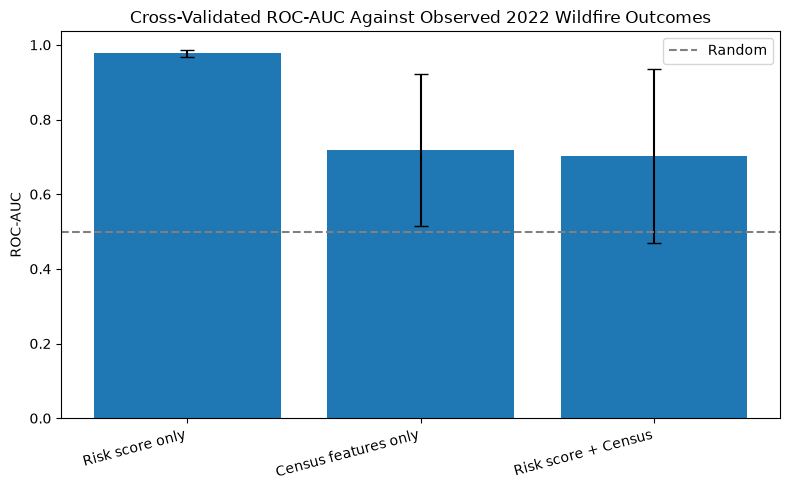

In [103]:
plt.figure(figsize=(8, 5))

plt.bar(comparison.index, comparison["mean_auc"], yerr=comparison["std_auc"], capsize=5)
plt.axhline(0.5, linestyle="--", color="grey", label="Random")

plt.title("Cross-Validated ROC-AUC Against Observed 2022 Wildfire Outcomes")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=15, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

## 3.3 Diagnosing the Result With Permutation Importance

The comparison above shows that adding Census features *reduced* held-out performance. Permutation
importance, computed on a single held-out fold, helps explain why — but it must be read carefully, and the
result below is initially counter-intuitive.

Permutation importance measures the drop in performance when one feature's values are randomly shuffled,
which reflects how much the fitted model relied on that feature *within the data it is being scored on*.

**In plain terms.** Permutation importance works by sabotage. The fitted model is scored on held-out data,
then one feature's values are shuffled at random — destroying any relationship it had with the outcome
while leaving everything else intact — and the model is scored again. The drop in performance is that
feature's importance.

A feature with importance near zero is one the model was not relying on. A small negative value simply
means shuffling made no difference and the noise went the other way; it should be read as "no contribution"
rather than as a harmful feature.

In [104]:

import gc
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

# 1. Select only columns needed for modelling
feature_columns = list(
    dict.fromkeys(["risk_score_prediction"] + CENSUS_FEATURES)
)

required_columns = feature_columns + [
    "burned_2022",
    "county_fips"
]

# Avoid copying the full GeoDataFrame
fit_data = pd.DataFrame(
    model_base[required_columns]
).dropna(
    subset=["burned_2022", "county_fips"]
)

# 2. Reduce numeric memory usage
X_all = fit_data[feature_columns].astype("float32")

y_all = fit_data["burned_2022"].to_numpy(
    dtype=np.int8
)

groups_all = fit_data["county_fips"].to_numpy()

# 3. County-grouped train/test split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_all, y_all, groups_all)
)

# 4. Train model
final_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    random_state=42
)

final_model.fit(
    X_all.iloc[train_idx],
    y_all[train_idx]
)

# 5. Sample test data for permutation importance
# Keeps computation manageable
rng = np.random.default_rng(42)

MAX_TEST_ROWS = 20000

if len(test_idx) > MAX_TEST_ROWS:
    selected_idx = rng.choice(
        test_idx,
        size=MAX_TEST_ROWS,
        replace=False
    )
else:
    selected_idx = test_idx

X_test = X_all.iloc[selected_idx]
y_test = y_all[selected_idx]

# ROC-AUC requires both classes
if np.unique(y_test).size < 2:
    raise ValueError(
        "Test sample contains only one class. "
        "Use a larger or stratified sample."
    )

# 6. Calculate permutation importance
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# 7. Create feature importance table
importance_frame = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": importance.importances_mean,
        "std": importance.importances_std
    })
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# 8. Free temporary memory
del fit_data, X_test, y_test
gc.collect()

importance_frame


,feature,importance,std
0,risk_score_prediction,0.443987,0.035704
1,owner_occupied_housing_units_median_value,0.087038,0.034494
2,detached_housing_share,0.066403,0.037610
3,population_density,0.040878,0.000669
4,housing_density,0.039678,0.000451
5,mobile_home_share,-0.017990,0.017096
6,median_year_structure_built,-0.032326,0.066629
7,income_per_capita,-0.054634,0.037020
8,vacancy_rate,-0.184127,0.019449


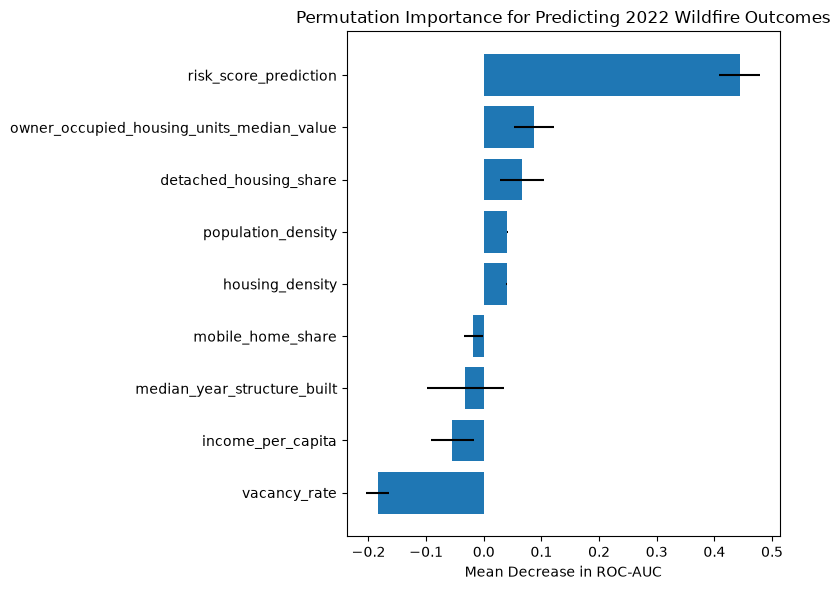

In [105]:
plt.figure(figsize=(8, 6))

ordered = importance_frame.sort_values("importance")

plt.barh(ordered["feature"], ordered["importance"], xerr=ordered["std"])
plt.title("Permutation Importance for Predicting 2022 Wildfire Outcomes")
plt.xlabel("Mean Decrease in ROC-AUC")

plt.tight_layout()
plt.show()

## 3.4 Findings

### Census features did not improve performance in the saved run

| Model | Mean ROC-AUC | Std across folds | Change vs score alone |
|---|---:|---:|---:|
| Risk score only | **0.9777** | 0.0092 | — |
| Census features only | 0.7187 | 0.2046 | -0.2590 |
| Risk score + Census | 0.7016 | 0.2331 | **-0.2761** |

In the saved county-grouped five-fold evaluation, the risk score alone had the highest mean ROC-AUC and the lowest fold-to-fold variation. Adding Census features did not improve discrimination in counties held out from training. The substantial fold-to-fold variation means the comparison should be interpreted cautiously.

### Why geographic validation matters

All 920 observed perimeter-exposure cases were concentrated in 32 counties. County grouping keeps properties from the same county out of both training and testing simultaneously, reducing spatial leakage. The results are consistent with Census features being less transferable across geographic areas, but the analysis does not prove a single cause for the performance decline.

### Permutation importance: a separate diagnostic

The latest saved single-fold permutation-importance output ranked `risk_score_prediction` highest (mean ROC-AUC decrease approximately **0.444**). `vacancy_rate` had negative importance (approximately **-0.184**) on the sampled held-out data. This measures reliance of one fitted model on a particular test sample; it does not establish causation or reliable generalization across all folds. Recompute the importance after a clean run before using these values in a final report.

### Interpretation and limitations

- **Spatial concentration:** Exposure events are concentrated in a small number of counties, so grouped folds may vary substantially.
- **Feature resolution:** Tract-level Census features are shared by many properties and may miss parcel-level hazard differences.
- **Outcome limitation:** The label indicates intersection with a mapped 2022 wildfire perimeter, not confirmed structural damage.
- **Generalization:** One fire season is insufficient to establish performance in future seasons.
- **Next steps:** Evaluate multiple fire seasons and test hazard-specific features such as terrain, fuels, and wildland–urban interface proximity.


# Appendix: References and Methodology Notes

## A. External Data Sources

| Source | Publisher | Use |
|---|---|---|
| Wildfire risk dataset | Assessment (provided) | Property coordinates and 2022 risk scores |
| 2020 Census tract-level attributes | Provided with the assignment | Tract demographic, housing and economic variables |
| 2020 Cartographic Boundary Files, Census Tracts 1:500,000 | US Census Bureau | Mapping property coordinates to tract GEOIDs |
| Monitoring Trends in Burn Severity, burned area boundaries | USGS / USDA Forest Service | Observed 2022 wildfire outcomes for validation |
